In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style agar mirip dengan PDF (bersih, background putih)
sns.set_theme(style="white")
plt.rcParams['figure.dpi'] = 120

# Load dataset
df = pd.read_csv('../data/heart_disease_uci.csv')
print(f"Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")

Dataset berhasil dimuat: 920 baris, 16 kolom


In [11]:
# Menelaah Data: Info tipe data & missing values
print("Ukuran Dataset:", df.shape)
print("\n--- Tipe Data & Missing Values ---")
df.info()

Ukuran Dataset: (920, 16)

--- Tipe Data & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [12]:
# Membuat kolom 'Category' untuk meniru PDF
# 0 = Normal, 1-4 = Penyakit Jantung (Sakit)
df['Category'] = df['num'].apply(lambda x: 'NORMAL' if x == 0 else 'SAKIT JANTUNG')

# Cek distribusi kategori
print(df['Category'].value_counts())

Category
SAKIT JANTUNG    509
NORMAL           411
Name: count, dtype: int64


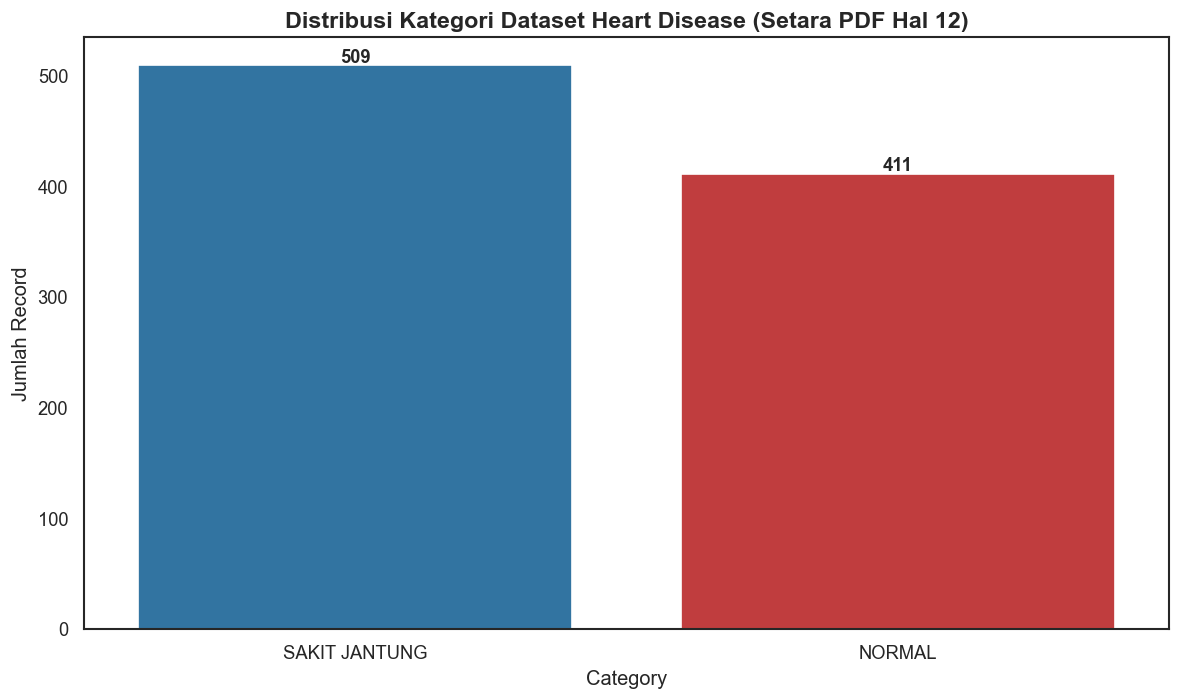

In [13]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette=['#1f77b4', '#d62728'])

plt.title('Distribusi Kategori Dataset Heart Disease (Setara PDF Hal 12)', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Jumlah Record', fontsize=12)

# Menambahkan angka di atas bar (seperti di PDF)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 5), 
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

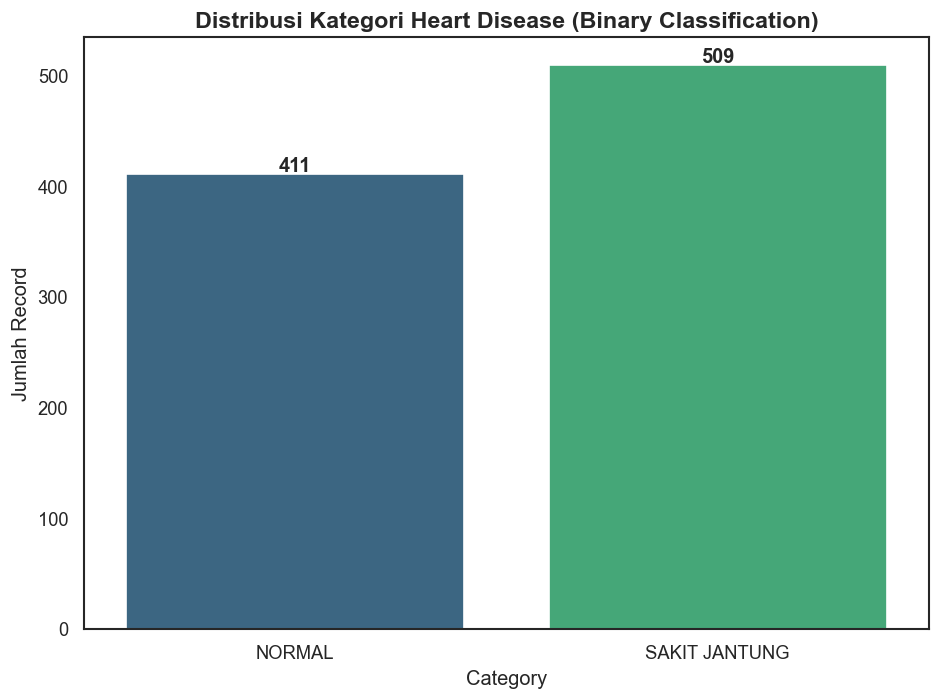

In [14]:
# Meniru PDF Hal 13 & 14: Fokus pada Binary Classification
plt.figure(figsize=(8, 6))
ax = sns.countplot(data=df, x='Category', palette='viridis')

plt.title('Distribusi Kategori Heart Disease (Binary Classification)', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Jumlah Record', fontsize=12)

# Menambahkan angka persis seperti di PDF Hal 14
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 5), 
                textcoords='offset points',
                fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

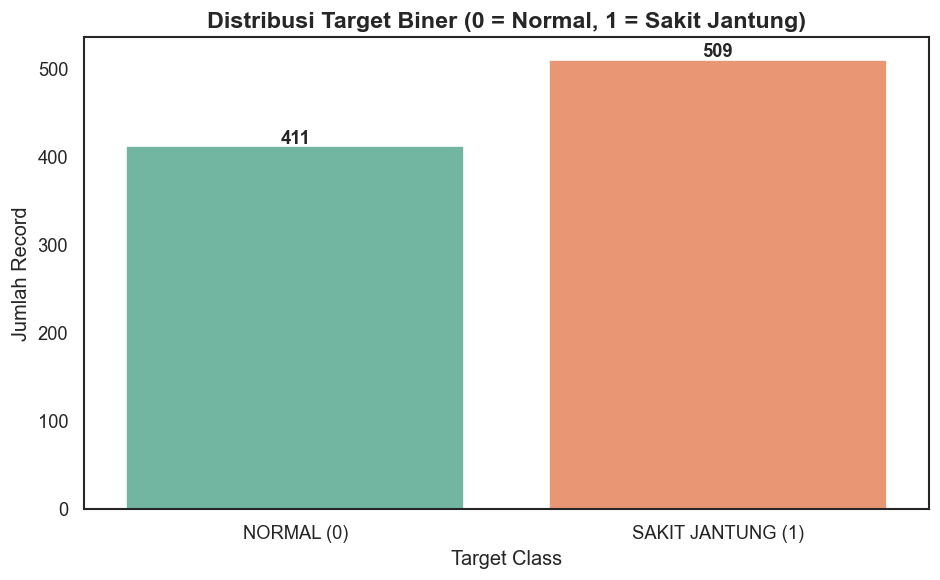

In [15]:
# Kolom 'target' yang dipakai oleh model (0 = Normal, 1 = Sakit)
df['target'] = (df['num'] > 0).astype(int)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='target', palette='Set2')

plt.title('Distribusi Target Biner (0 = Normal, 1 = Sakit Jantung)', fontsize=14, fontweight='bold')
plt.xticks([0, 1], ['NORMAL (0)', 'SAKIT JANTUNG (1)'])
plt.xlabel('Target Class', fontsize=12)
plt.ylabel('Jumlah Record', fontsize=12)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 5), 
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### Kesimpulan Visualisasi:
1. **Bar Chart 1 (Setara PDF Hal 12):** Menunjukkan komposisi data secara keseluruhan. Pasien yang didiagnosis menderita penyakit jantung (509) lebih banyak dibandingkan pasien normal (411).
2. **Bar Chart 2 (Setara PDF Hal 13 & 14):** Mempertegas bahwa dataset ini siap digunakan untuk **Binary Classification** (Klasifikasi Biner), yaitu membedakan antara kelas NORMAL dan SAKIT JANTUNG.
3. **Bar Chart 3:** Menunjukkan data `target` dalam format 0 dan 1 yang nantinya akan dikonsumsi langsung oleh algoritma *Machine Learning* (Logistic Regression) pada tahap *Training*.

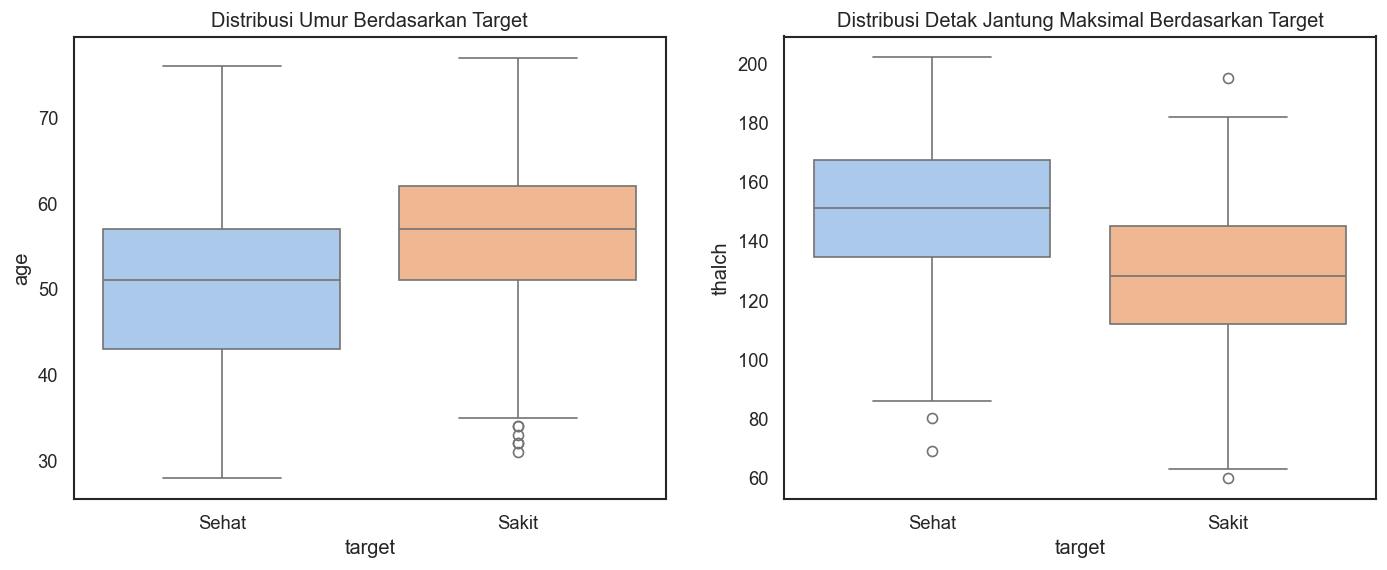

In [19]:
# Melihat sebaran umur dan detak jantung maksimal berdasarkan target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(ax=axes[0], data=df, x='target', y='age', palette='pastel')
axes[0].set_title('Distribusi Umur Berdasarkan Target')
axes[0].set_xticklabels(['Sehat', 'Sakit'])

sns.boxplot(ax=axes[1], data=df, x='target', y='thalch', palette='pastel')
axes[1].set_title('Distribusi Detak Jantung Maksimal Berdasarkan Target')
axes[1].set_xticklabels(['Sehat', 'Sakit'])

plt.show()

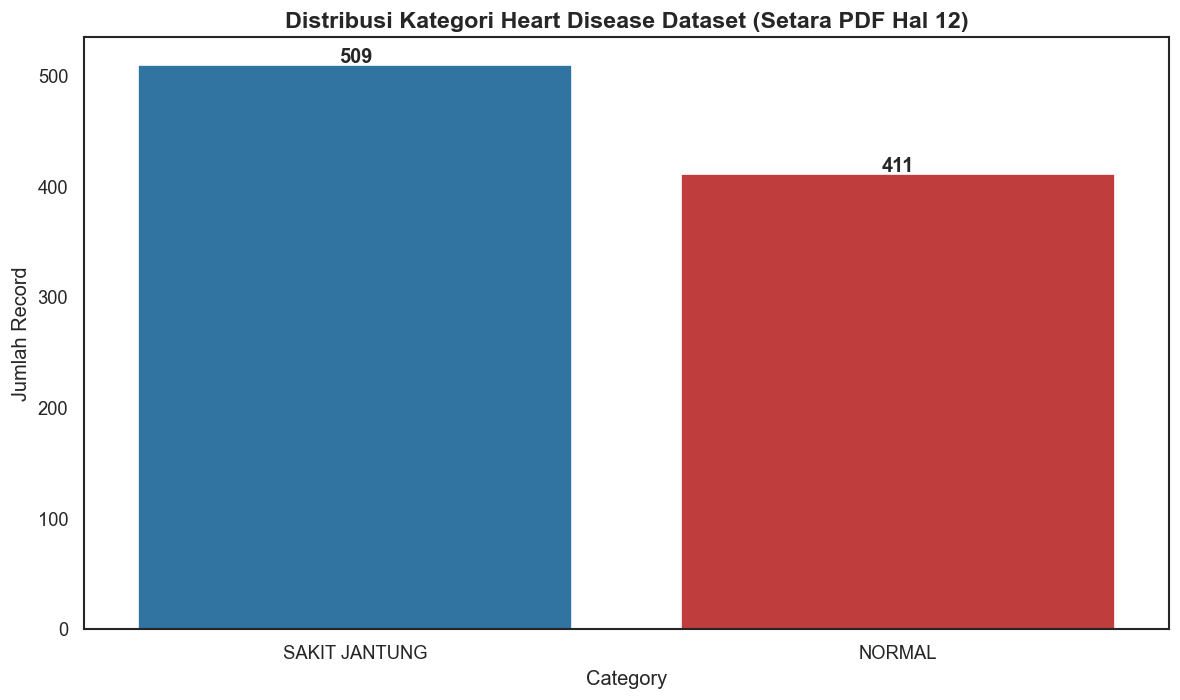

In [20]:
# Meniru PDF Hal 12: Distribusi Kategori (sebelum filter biner)
plt.figure(figsize=(10, 6))

# Urutkan kategori berdasarkan jumlahnya agar tampilan mirip PDF
order_cat = df['Category'].value_counts().index

ax = sns.countplot(
    data=df,
    x='Category',
    order=order_cat,
    palette=['#1f77b4', '#d62728']  # Biru & Merah, mirip PDF
)

plt.title('Distribusi Kategori Heart Disease Dataset (Setara PDF Hal 12)',
          fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Jumlah Record', fontsize=12)

# Tambahkan label angka di atas bar (persis seperti PDF hal 14)
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()

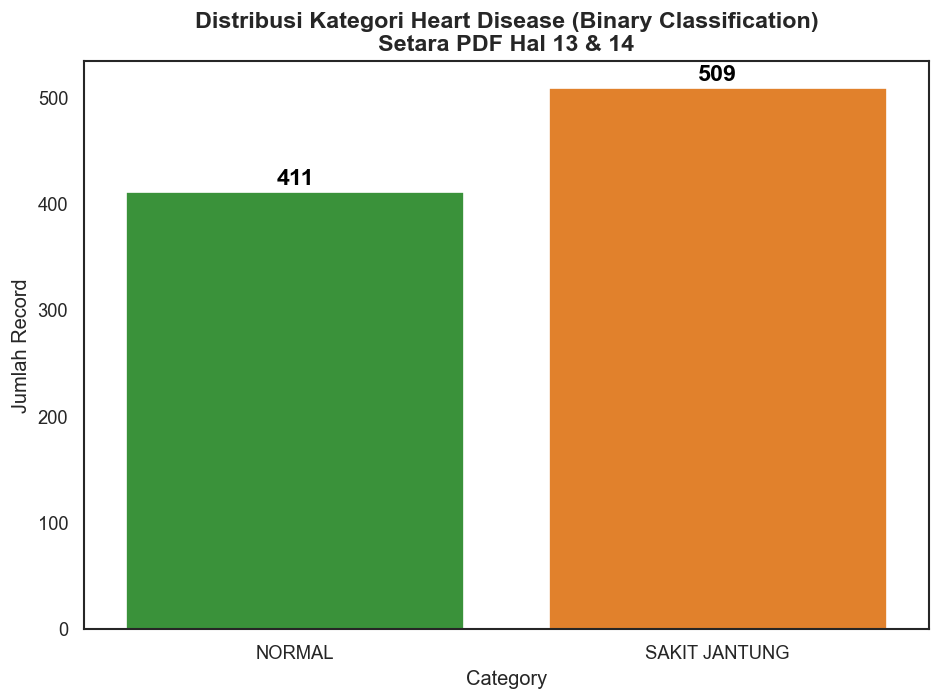

In [21]:
# Meniru PDF Hal 13 & 14: Binary Classification dengan Angka
plt.figure(figsize=(8, 6))

# Warna hijau & oranye, mirip dengan PDF hal 14
ax = sns.countplot(
    data=df,
    x='Category',
    order=['NORMAL', 'SAKIT JANTUNG'],
    palette=['#2ca02c', '#ff7f0e']
)

plt.title('Distribusi Kategori Heart Disease (Binary Classification)\nSetara PDF Hal 13 & 14',
          fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Jumlah Record', fontsize=12)

# Angka di atas bar, ukuran besar (persis PDF hal 14)
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 8),
        textcoords='offset points',
        fontsize=14, fontweight='bold',
        color='black'
    )

plt.tight_layout()
plt.show()

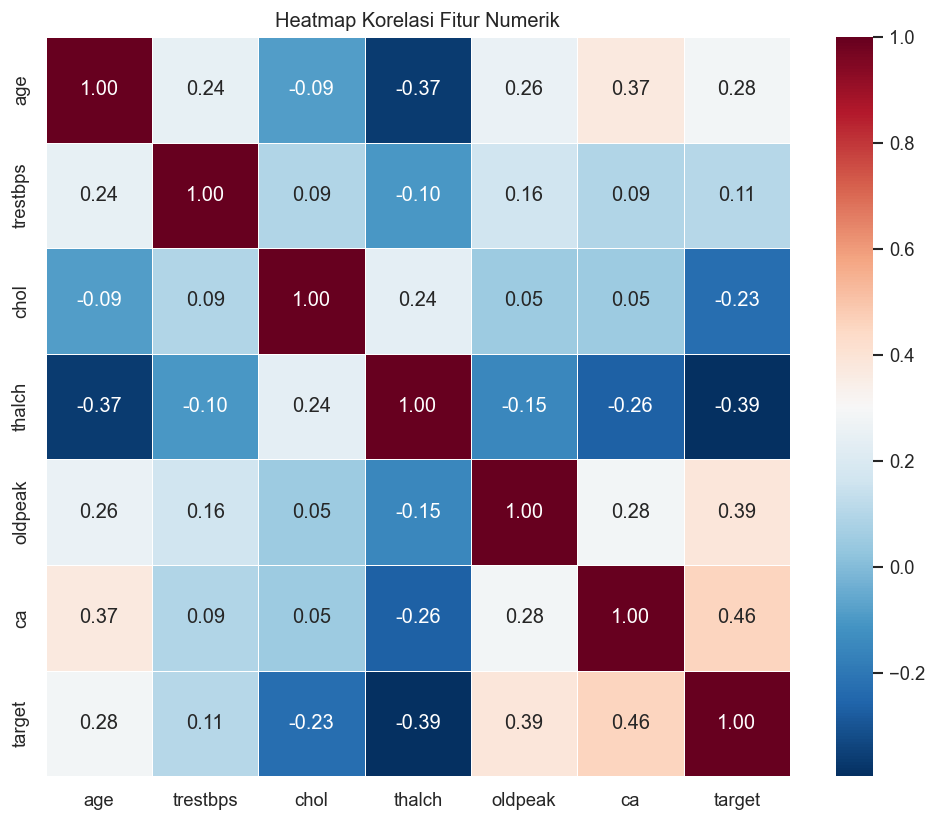

In [22]:
# Cek korelasi antar fitur numerik
plt.figure(figsize=(10, 8))
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'target']
corr_matrix = df[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt=".2f", linewidths=.5)
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

### Kesimpulan Eksplorasi Data (EDA):
1. **Distribusi Target:** Dataset didominasi oleh pasien dengan penyakit jantung (target 1). Distribusi biner cukup seimbang (509 Sakit vs 411 Sehat).
2. **Missing Values:** Terdapat banyak *missing values* pada kolom `ca`, `thal`, dan `slope`. Hal ini ditangani pada *pipeline* dengan imputasi median/modus.
3. **Korelasi:** Fitur `exang` (nyeri dada saat olahraga), `oldpeak`, dan `thalch` (detak jantung maks) memiliki korelasi yang cukup kuat terhadap target penyakit jantung.
4. **Jenis Kelamin:** Pasien laki-laki mendominasi dataset dan memiliki proporsi penyakit jantung yang lebih tinggi dibandingkan perempuan.